# **Thames Valley Crime Data Analysis**
## Modelling: Predicting Crime Counts
---

### Objectives

- Answer Key Question 5: can we predict the number of crimes for an area, crime type and month?
- Compare a baseline with models suitable for the data that we have, then decide which is the best.
- Test the chosen model on data that it has not seen.
- Explain any limitations.

### Planned Steps

1. Load, check and prepare the cleaned data
2. Split the data into training and test data
3. Find the baseline
4. Compare the models
5. Test the chosen model
6. Predict monthly totals from October 2026 to September 2027
7. Conclusions

### Inputs

`../data/clean/crime_summary.csv` - Crime counts per month, season, area and crime type.

The summary file is used rather than `crime_clean.csv`, because the model predicts **how many** crimes there are. It is much smaller (0.3 MB), so it is quicker to load.

### Key Questions explored in this notebook

5. Can monthly crime counts be predicted for an area and crime type, and if so, which model does it best?

### Outputs

- A model comparison and test scores.
- A chart comparing actual and predicted crime counts for the test year.
- A chart showing predicted monthly totals from October 2026 to September 2027.
- Answer to Key Question 5.

### Additional Comments

- Cells in this notebook run top to bottom.
- The model predicts **counts**, not **rates**. Larger areas naturally have more crime (see Limitations in the README).
- This is a **supervised regression** problem. The target ***Count*** is a number, and the model has real data to learn from.
- `random_state=101` is used in this notebook to keep the results the same each time the notebook is run.

---
### Setup

Import required libraries:

- `matplotlib` - to draw the chart.
- `numpy` - for numerical calculations.
- `pandas` - to load and split the data, and show results.
- `scikit-learn` - to prepare the data, and to build, test and score the models.

Note: `%matplotlib inline` is used so charts display inside the notebook (see Bugs in README).

In [1]:
# Import required libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Baseline and cross-validation
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate

# Prepare the columns for the models
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Models to compare
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# Scores for the test year
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ensures that charts are displayed correctly in the notebook
%matplotlib inline

print("Libraries imported successfully")

Libraries imported successfully


---
### 1. Load, check and prepare the cleaned data

Here we will load and check the summary data to make sure nothing was lost or changed since we saved `crime_summary.csv` at the end of `01_ETL.ipynb`, and that it is ready for modelling.

We predict ***Count*** using ***Area***, ***Crime type*** and the **month**.

We will use **supervised learning**, as the data has a target (***Count***) for the model to learn from. It is a regression problem, because the target is a number.

We will prepare our data using **cyclical encoding**, so the models see the months as a continuous loop.

The year is not used, as from answering Question 3 we already know that crime only fell 0.307% (595 fewer crimes) from Year 1 to Year 3 - so it effectively stayed level.

In [2]:
# Load the data
summary = pd.read_csv("../data/clean/crime_summary.csv",
                      parse_dates=["Month"])

# Print the size, total crimes, missing values and column types
print("Rows and columns:", summary.shape)
print("Total crimes:", summary["Count"].sum())
print("Missing values:", summary.isnull().sum().sum())
summary.info()

summary.head()

Rows and columns: (6552, 5)
Total crimes: 579772
Missing values: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6552 entries, 0 to 6551
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Month       6552 non-null   datetime64[ns]
 1   Season      6552 non-null   object        
 2   Area        6552 non-null   object        
 3   Crime type  6552 non-null   object        
 4   Count       6552 non-null   int64         
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 256.1+ KB


,Month,Season,Area,Crime type,Count
0,2023-10-01,Autumn,Bracknell Forest,Anti-social behaviour,81
1,2023-10-01,Autumn,Buckinghamshire,Anti-social behaviour,306
2,2023-10-01,Autumn,Cherwell,Anti-social behaviour,90
3,2023-10-01,Autumn,Milton Keynes,Anti-social behaviour,171
4,2023-10-01,Autumn,Oxford,Anti-social behaviour,125


We can see from the above that:
- the data has 6,552 rows, 5 columns, a total of 579,772 crimes and no missing values, all matching `01_ETL.ipynb`.
- ***Month*** was loaded as a date.
- nothing was lost or changed, so the data is ready to be prepared for modelling.

Next, we place the month into a loop using cyclical encoding.

In [3]:
# Place each month into a loop
month_number = summary["Month"].dt.month
summary["month_sin"] = np.sin(2 * np.pi * month_number / 12)
summary["month_cos"] = np.cos(2 * np.pi * month_number / 12)

# Show one row per month to check cyclical encoding
months = summary.drop_duplicates(["Month"]).head(36)
months[["Month", "month_sin", "month_cos"]].round(2)

,Month,month_sin,month_cos
0,2023-10-01,-0.87,0.50
13,2023-11-01,-0.50,0.87
26,2023-12-01,-0.00,1.00
39,2024-01-01,0.50,0.87
52,2024-02-01,0.87,0.50
65,2024-03-01,1.00,0.00
78,2024-04-01,0.87,-0.50
91,2024-05-01,0.50,-0.87
104,2024-06-01,0.00,-1.00
117,2024-07-01,-0.50,-0.87


Each month now has its own pair of values (sine (sin) and cosine (cos)). As we have asked for the full 36 months of data we can now see that the same values repeat each year, so the model sees each month as the same every year.

Because crime stayed the same level each year (only 0.307% lower, **Question 3**), leaving out the year makes little difference. This is noted as a limitation in the conclusions.

---
### 2. Split the data into training and test data

We now need to carry out a train test split as the model needs to train on one part and we test on the other.

We split the data by date rather than at random as the data is in time order, so it uses the past to predict the future.

We have 3 years of data, so we will train on the first 2 years, and test on the 3rd year. The features go into **X** and the target into **y** (the ***Count***).

In [4]:
# Train on the first two years, test on the final year
train = summary[summary["Month"] < "2025-10-01"]
test = summary[summary["Month"] >= "2025-10-01"]

# Columns the model learns from and the column it predicts
features = ["Area", "Crime type", "month_sin", "month_cos"]
X_train, y_train = train[features], train["Count"]
X_test, y_test = test[features], test["Count"]

print("Training set size:", train.shape)
print("Test set size:", test.shape)

Training set size: (4368, 7)
Test set size: (2184, 7)


The split was successful. We now have a training set of 2 years, which is 4,368 rows (October 2023 to September 2025), and a test set of 1 year, which is 2,184 rows (October 2025 to September 2026).

---
### 3. Find the baseline

In order to judge any model we need a benchmark to compare it against. The **baseline** predicts the **average** crime count from the training data for every row. **The baseline** then becomes the measurement that any useful model needs to beat.

To validate the baseline we will use **k-fold cross-validation** (k = 5). This is done by splitting the training data into 5 parts, and each part gets a turn as the test part. All of the tests are then averaged to give us a fairer score than if only one were used.

**The scores used are:**
- **R<sup>2</sup>:** How well the model explains changes in crime counts, from 0 to 1, with higher (closer to 1) being better. The baseline is near zero, as it guesses the same average.
- **MAE (mean absolute error):** How many crimes a prediction is off by, on average (lower is better).
- **RMSE (root mean squared error):** Like MAE, but big errors count for more (lower is better).

In [5]:
# Scores to measure
scoring = {
    "r": "r2", 
    "mae": "neg_mean_absolute_error", 
    "rmse": "neg_root_mean_squared_error",
}

baseline = DummyRegressor(strategy="mean")
baseline_scores = cross_validate(baseline, X_train, y_train, cv=5, 
                                 scoring=scoring)

print("Average count in the training data:", round(y_train.mean(), 1))
print("Baseline R2 score:", round(baseline_scores["test_r"].mean(), 3))
print("Baseline MAE score:", round(-baseline_scores["test_mae"].mean(), 1))
print("Baseline RMSE score:", round(-baseline_scores["test_rmse"].mean(), 1))

Average count in the training data: 88.5
Baseline R2 score: -0.363
Baseline MAE score: 85.5
Baseline RMSE score: 118.8


The baseline **R<sup>2</sup>** is -0.363, which is much lower than expected. A baseline that guesses the average should score close to 0.

After investigating the data, we can see that at the end of `01_ETL.ipynb` the dataset `crime_summary.csv` was saved in ***Crime type*** order, so when the rows are split into 5 above without shuffling them, each test part contains whole crime types.
This would then mean that the baseline's average is compared against crime types that were left out of its training parts, which gives a misleading score.

To fix this, the rows need to be shuffled before the 5-part split.

In [6]:
# Split the training data into 5 shuffled folds
folds = KFold(n_splits=5, shuffle=True, random_state=101)

# Baseline again, using the shuffled folds
baseline_scores = cross_validate(baseline, X_train, y_train, cv=folds, 
                                 scoring=scoring)

print("Average count in the training data:", round(y_train.mean(), 1))
print("Baseline R2 score:", round(baseline_scores["test_r"].mean(), 3))
print("Baseline MAE score:", round(-baseline_scores["test_mae"].mean(), 1))
print("Baseline RMSE score:", round(-baseline_scores["test_rmse"].mean(), 1))

Average count in the training data: 88.5
Baseline R2 score: -0.001
Baseline MAE score: 82.3
Baseline RMSE score: 142.8


With the rows shuffled, the baseline **R<sup>2</sup>** is -0.001, which is now close to 0 as we expected. `random_state=101` makes the shuffle the same every time the notebook is run, so the same results are repeated.

The **baseline** guesses 88.5 crimes for every row. On average its predictions are 82.3 crimes out (**MAE**), and its **RMSE** is 142.8, close to the **standard deviation** (143.4) that we found in `02_EDA.ipynb`.

**These are the scores that our models need to beat to be considered useful.**

---
### 4. Compare the models

As we have a regression problem that we are trying to solve, we will test 4 models that are suitable for this:
- **Linear regression** - the simplest model, which fits a straight line.

and three tree models, from simplest to most complex:
- **Decision tree** - a single flowchart of yes and no questions.
- **Random forest** - many trees, with their answers averaged.
- **Gradient boosting** - trees built one after the other, each fixing the mistakes of the last one.

To compare the models fairly we run each model using the same code with a different model name, checked with k-fold cross-validation using the same metrics as the baseline.


To do this we first need to:
1. Use **one-hot encoding** to turn ***Area*** and ***Crime type*** into separate 0 and 1 columns.
2. Use **scaling** to put the month columns on the same scale.

These steps make up part of the **pipeline** with the model, so they are only learned from the training data.

After the tests are complete, we can look at the scores to consider if the model is either:
- **underfitting** - the model is too simple to find the pattern, so it has a low **R<sup>2</sup>** on both the training and cross-validation tests.
- **overfitting** - the model has learned the training data too closely and it then performs badly on new data, so its training **R<sup>2</sup>** is much higher than the cross-validation **R<sup>2</sup>**.

In [7]:
# One-hot encode area and crime columns and scale month columns
preprocess = ColumnTransformer([
    ("categories", OneHotEncoder(handle_unknown="ignore"),
     ["Area", "Crime type"]),
    ("months", StandardScaler(), ["month_sin", "month_cos"])
])

# Models to compare
models = {
    "Baseline (Average)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=101),
    "Random Forest": RandomForestRegressor(random_state=101),
    "Gradient Boosting": GradientBoostingRegressor(random_state=101),
}

# Cross-validate each model on the training data
rows = []
for name, model in models.items():
    pipeline = Pipeline([("prep", preprocess),("model", model)])
    scores = cross_validate(pipeline, X_train, y_train, cv=folds, 
                            scoring=scoring, return_train_score=True)
    rows.append({
        "Model": name,
        "Training R2": round(scores["train_r"].mean(), 3),
        "Cross Validation R2": round(scores["test_r"].mean(), 3),
        "Cross Validation MAE": round(-scores["test_mae"].mean(), 1),
        "Cross Validation RMSE": round(-scores["test_rmse"].mean(), 1)
    })

# Show results
results = pd.DataFrame(rows)
results

,Model,Training R2,Cross Validation R2,Cross Validation MAE,Cross Validation RMSE
0,Baseline (Average),0.000,-0.001,82.3,142.8
1,Linear Regression,0.749,0.744,38.1,72.2
2,Decision Tree,0.994,0.972,14.4,23.6
3,Random Forest,0.993,0.980,12.3,20.2
4,Gradient Boosting,0.961,0.957,19.2,29.3


#### Findings - Model comparison

- All 4 models beat the **baseline** (cross-validation **R<sup>2</sup>** of -0.001, **MAE** of 82.3), shown in the first row of the table above.
- **Linear regression** scores the lowest of the 4 models we tested (cross-validation **R<sup>2</sup>** of 0.744, **MAE** of 38.1), meaning it is too simple to capture how the area and crime type combine, so it is **underfitting**.
- **Random forest** has the highest cross-validation **R<sup>2</sup>** (0.980), the lowest MAE (12.3) and RMSE (20.2).
- **Decision tree** is close behind **Random forest** (cross-validation **R<sup>2</sup>** of 0.972), but has the biggest gap between its training **R<sup>2</sup>** (0.994) and cross-validation **R<sup>2</sup>** (0.972). This means it is **slightly overfitting**.
- **Gradient boosting** has almost no gap between its training **R<sup>2</sup>** (0.961) and cross-validation (0.957), but it scores lower than the other tree models. 

**After considering the results above, *Random forest* is the model we will choose.**

---
### 5. Test the chosen model

We will now train our chosen model, **Random forest**, on the first two years of data. We will then give it the third year (which it has not yet seen), to see how well it performs. It is tested once, so that it is a fair check on the new data.

The model will be given the ***Area***, ***Crime type*** and **month** for each row and it will then predict the count. We will then measure the predictions against the real counts using the same metrics as before, **R<sup>2</sup>**, **MAE** and **RMSE**.

In [8]:
# Train the model on the first two years
chosen_model = "Random Forest"
final_model = Pipeline([("prep", preprocess),
                        ("model", models[chosen_model])])
final_model.fit(X_train, y_train)

# Predict the third year and show the results
predictions = final_model.predict(X_test)

print("Model:", chosen_model)
print("R2:", round(r2_score(y_test, predictions), 3))
print("MAE:", round(mean_absolute_error(y_test, predictions), 1))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 1))

Model: Random Forest
R2: 0.982
MAE: 12.0
RMSE: 19.1


To make the result easier to compare, we will put the third year's scores in a table alongside the cross-validation scores for **Random forest** and the baseline.

In [9]:
# Cross-validation scores for the baseline and chosen model
comparison = results.set_index("Model").loc[
    ["Baseline (Average)", chosen_model], 
    ["Cross Validation R2", "Cross Validation MAE", "Cross Validation RMSE"]]
comparison.columns = ["R2", "MAE", "RMSE"]

# Add chosen model scores for the third year
comparison.loc[chosen_model + " (Third Year)"] = [
    round(r2_score(y_test, predictions), 3),
    round(mean_absolute_error(y_test, predictions), 1),
    round(np.sqrt(mean_squared_error(y_test, predictions)), 1)
]

comparison

,R2,MAE,RMSE
Model,,,
Baseline (Average),-0.001,82.3,142.8
Random Forest,0.980,12.3,20.2
Random Forest (Third Year),0.982,12.0,19.1


In the table above we can now clearly make a comparison between the scores from Section 4 (where we tested the models), and the scores for the third year.

On year three **Random forest** has an **R<sup>2</sup>** of 0.982, **MAE** of 12.0 crimes and **RMSE** of 19.1. These scores are slightly better than its cross-validation scores across all metrics, so the model works well on data it has not yet seen and it is not **overfitting**. It is also far better than the baseline.

#### The pipeline

So we can see the steps inside the pipeline of our chosen model, **Random forest**, and to see what is happening at each stage, we can create a diagram of it (each box can be clicked to show its settings).

In [10]:
# Show steps inside our final model pipeline
final_model

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('categories',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Area', 'Crime type']),
                                                 ('months', StandardScaler(),
                                                  ['month_sin',
                                                   'month_cos'])])),
                ('model', RandomForestRegressor(random_state=101))])

The diagram shows our pipeline. The ***Area*** and ***Crime type*** are one-hot encoded (turning the text into 0 and 1 columns), so the model can use them. At the same time, the month columns are scaled, and then all are passed to our **Random forest** model.

#### Actual vs predicted

To visualise the results above, we will create a scatter plot. By doing so, we will be able to see the real counts for the third year against the predictions.

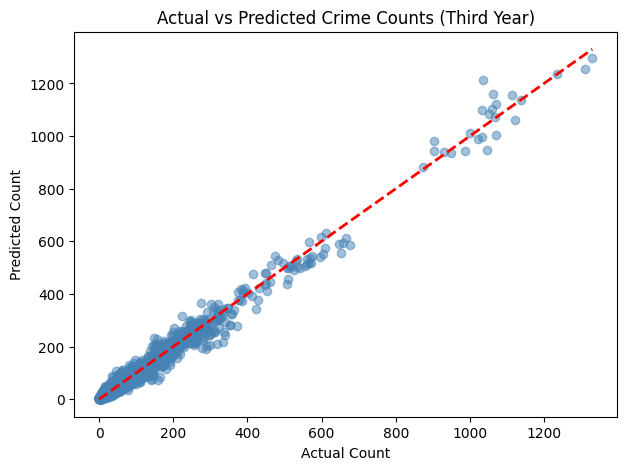

In [11]:
# Actual vs predicted counts for the third year
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_test, predictions, alpha=0.5, color="steelblue")

# Add correct prediction line
ax.plot([0, y_test.max()], [0, y_test.max()], color="red", linestyle="--",
        linewidth=2)

ax.set_xlabel("Actual Count")
ax.set_ylabel("Predicted Count")
ax.set_title("Actual vs Predicted Crime Counts (Third Year)")

plt.show()

Each dot is one ***Area***, ***Crime type*** and **month**. Dots on the red line were predicted exactly; the further the dot is from the line, the bigger the error.

We can see that most of the dots sit next to, or on, the red line. The biggest errors are at the higher counts.

---
### 6. Predict monthly totals from October 2026 to September 2027

Now we know how accurate the model is, we can now use it to predict the number of crimes for the next year (October 2026 to September 2027).

To do this we will first retrain the model on all three years of data that we have.

In [12]:
# Retrain the model on all three years of data
final_model.fit(summary[features], summary["Count"])

print("Retrain on all three years data completed")

Retrain on all three years data completed


We will now create a table of data for the year we are predicting, with months, areas and crime types, and then ask the model to predict the counts.

**Note:** we will only do this for one year. This model does not use the year, so predicting further ahead would repeat the same monthly pattern. Predictions are less reliable the further ahead they go (This will be added to the limitations in this notebook and the README).

In [13]:
# Use the same areas and crime types and move 1 year ahead
future = test[["Month", "Area", "Crime type"]].copy()
future["Month"] = future["Month"] + pd.DateOffset(years=1)

# Add the month columns and predict counts for year 4
month_number = future["Month"].dt.month
future["month_sin"] = np.sin(2 * np.pi * month_number / 12)
future["month_cos"] = np.cos(2 * np.pi * month_number / 12)
future["Predicted"] = final_model.predict(future[features]).round()

# Display the total monthly predicted crime counts
future.groupby("Month")["Predicted"].sum().astype(int)

Month
2026-10-01    16516
2026-11-01    15713
2026-12-01    14546
2027-01-01    14789
2027-02-01    14133
2027-03-01    16008
2027-04-01    15909
2027-05-01    17073
2027-06-01    17217
2027-07-01    18321
2027-08-01    17105
2027-09-01    15986
Name: Predicted, dtype: int32

Our model predicts the crime counts for year 4, showing a monthly count of crimes for the Thames Valley.

The model predicts that the lowest counts are in the winter months (December, January and February), with the lowest in February (14,133). Counts then rise from March and into the summer (June, July and August), peaking in July (18,321), after which they start to fall again.

The above is in line with what we observed in Question 4.

#### Visualise our prediction

To make the year 4 prediction clearer, we will now create a line graph to visualise what we have learnt. It will show us the actual monthly totals for the last 3 years, continuing with plots for our year 4 predictions.

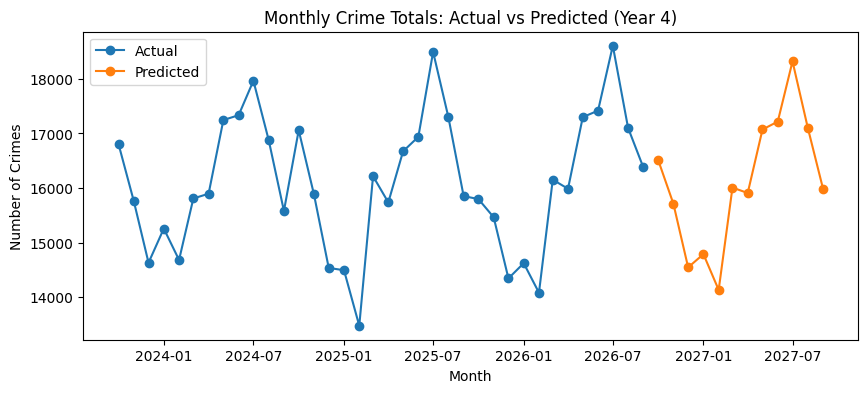

In [18]:
# Actual monthly totals and predicted monthly totals for year 4
actual_totals = summary.groupby("Month")["Count"].sum()
predicted_totals = future.groupby("Month")["Predicted"].sum()

# Draw line chart
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(actual_totals.index, actual_totals.values, marker="o", label="Actual")
ax.plot(predicted_totals.index, predicted_totals.values, marker="o", label="Predicted")

ax.set_title("Monthly Crime Totals: Actual vs Predicted (Year 4)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Crimes")
ax.legend()

plt.show()